# Phase 1: Book Cover CLIP Analysis

In Phase 1 we were asked to treat the modela s a black box and not use AI tools. So in this notebook, we as human-only pair tried to inspect the dataset, check the label structure, run the model on the image set, summarize performance, and save the results in a way that is easy to review and present.



## 1. Imports and setup

In [31]:
# Import packages
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from pathlib import Path

# Resolve paths relative to the notebook location
NOTEBOOK_ROOT = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_ROOT.parent
DATA_DIR = PROJECT_ROOT / 'archive'
OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'phase1_standalone'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'Notebook root: {NOTEBOOK_ROOT}')
print(f'Project root: {PROJECT_ROOT}')
print(f'Data directory: {DATA_DIR}')
print(f'Output directory: {OUTPUT_DIR}')

# Set random seed for reproducibility
SEED = 42
np.random.seed(SEED)


Notebook root: /Users/darina/Desktop/JKU_AI_Masterr/YEAR 2/AI & VISUALIZATION/MarshmallowBunnies/notebooks
Project root: /Users/darina/Desktop/JKU_AI_Masterr/YEAR 2/AI & VISUALIZATION/MarshmallowBunnies
Data directory: /Users/darina/Desktop/JKU_AI_Masterr/YEAR 2/AI & VISUALIZATION/MarshmallowBunnies/archive
Output directory: /Users/darina/Desktop/JKU_AI_Masterr/YEAR 2/AI & VISUALIZATION/MarshmallowBunnies/outputs/phase1_standalone


## 2. Load and validate the data



In [32]:
train_path = DATA_DIR / 'book30-listing-train.csv'
test_path = DATA_DIR / 'book30-listing-test.csv'
train_labels_path = DATA_DIR / 'bookcover30-labels-train.txt'
test_labels_path = DATA_DIR / 'bookcover30-labels-test.txt'
image_root = DATA_DIR / 'title30cat' / '224x224'

for path in [train_path, test_path, train_labels_path, test_labels_path, image_root]:
    print(path, 'exists:', path.exists())

if not train_path.exists() or not test_path.exists():
    raise FileNotFoundError('Expected dataset CSV files are missing from the dedicated dataset folder.')


def read_dataset_csv(path):
    return pd.read_csv(path, sep=';', engine='python', on_bad_lines='skip', encoding='utf-8-sig')


def read_label_file(path):
    return pd.read_csv(path, sep=r'\s+', header=None, names=['Filename', 'Category ID'], engine='python')


train_df = read_dataset_csv(train_path)
test_df = read_dataset_csv(test_path)
train_labels = read_label_file(train_labels_path)
test_labels = read_label_file(test_labels_path)

category_lookup = pd.concat([
    train_df[['Category ID', 'Category']],
    test_df[['Category ID', 'Category']]
]).drop_duplicates().set_index('Category ID')['Category'].to_dict()

train_labels['category_name'] = train_labels['Category ID'].map(category_lookup)
test_labels['category_name'] = test_labels['Category ID'].map(category_lookup)

train_df = train_df.merge(train_labels[['Filename', 'category_name']], on='Filename', how='left')
test_df = test_df.merge(test_labels[['Filename', 'category_name']], on='Filename', how='left')

train_df['category_name'] = train_df['category_name'].fillna(train_df['Category'])
test_df['category_name'] = test_df['category_name'].fillna(test_df['Category'])

CLASS_NAMES = sorted(test_df['category_name'].dropna().unique().tolist())

print('Train rows:', len(train_df))
print('Test rows:', len(test_df))
print('Column check:', list(train_df.columns[:12]))
print(train_df[['Filename', 'category_name']].head())

/Users/darina/Desktop/JKU_AI_Masterr/YEAR 2/AI & VISUALIZATION/MarshmallowBunnies/archive/book30-listing-train.csv exists: True
/Users/darina/Desktop/JKU_AI_Masterr/YEAR 2/AI & VISUALIZATION/MarshmallowBunnies/archive/book30-listing-test.csv exists: True
/Users/darina/Desktop/JKU_AI_Masterr/YEAR 2/AI & VISUALIZATION/MarshmallowBunnies/archive/bookcover30-labels-train.txt exists: True
/Users/darina/Desktop/JKU_AI_Masterr/YEAR 2/AI & VISUALIZATION/MarshmallowBunnies/archive/bookcover30-labels-test.txt exists: True
/Users/darina/Desktop/JKU_AI_Masterr/YEAR 2/AI & VISUALIZATION/MarshmallowBunnies/archive/title30cat/224x224 exists: True


Train rows: 51300
Test rows: 5700
Column check: ['Amazon Index (ASIN)', 'Filename', 'Image URL', 'Title', 'Author', 'Category ID', 'Category', 'category_name']
         Filename                 category_name
0  1588345297.jpg         Biographies & Memoirs
1  1404803335.jpg              Children's Books
2  1446276082.jpg  Engineering & Transportation
3  1491522666.jpg      Christian Books & Bibles
4  0970096410.jpg             Sports & Outdoors


In [33]:
# Check for missing values in the test split
missing = test_df.isna().sum()
print('Missing values in test split:')
print(missing[missing > 0])


Missing values in test split:
Author    397
dtype: int64


Showed that author is missing for 397 entries. This is not a problem for our use-case since we want to focus more on genres and covers.

## 3. Load and setup the model



In [ ]:
# Get the model and processor for CLIP
try:
    import torch
    from transformers import CLIPProcessor, CLIPModel
    print('Torch and transformers imported successfully.')
except Exception as e:
    raise RuntimeError(f'Could not import CLIP dependencies in this environment: {e}')

MODEL_NAME = 'openai/clip-vit-base-patch32'

model = CLIPModel.from_pretrained(MODEL_NAME)
processor = CLIPProcessor.from_pretrained(MODEL_NAME)
model.eval()

print('CLIP model loaded:', MODEL_NAME)

# Example run for a single image to validate the pipeline.
example_path = image_root / next(p for p in image_root.iterdir() if p.is_file())
example_pred, example_conf, example_probs = classify_image(example_path)
print('Example prediction:', example_pred)
print('Example confidence:', round(example_conf, 4))


Torch and transformers imported successfully.


CLIP model loaded: openai/clip-vit-base-patch32
Example prediction: Politics & Social Sciences
Example confidence: 0.9507


## 4. Experiment with the model

In [ ]:
# Prepare prompt templates
prompt_templates = [
    'a book cover in the genre {}',
    'a {} book cover',
    'a cover for a {} book'
]

# Function to get the image path from a row in the dataset
def get_image_path(row):
    filename = (
        row.get('Filename')
        or row.get('filename')
        or row.get('image')
        or row.get('cover')
    )
    if filename is None:
        raise ValueError('No image filename column found in the dataset schema.')
    return image_root / str(filename)

# Create a function to classify an image using the CLIP model
def classify_image(image_path, prompt_style='neutral'):
    image = Image.open(image_path).convert('RGB')
    prompt_choices = []
    for category in CLASS_NAMES:
        if prompt_style == 'neutral':
            prompt_choices.append(f'a book cover in the genre {category}')
        elif prompt_style == 'descriptive':
            prompt_choices.append(f'a visually rich book cover with a strong {category} mood')
        else:
            prompt_choices.append(f'a book cover in the genre {category}')

    inputs = processor(
        text=prompt_choices,
        images=image,
        return_tensors='pt',
        padding=True,
    )

    with torch.no_grad():
        outputs = model(**inputs)
        logits_per_image = outputs.logits_per_image
        probs = logits_per_image.softmax(dim=1).cpu().numpy()[0]

    idx = int(np.argmax(probs))
    pred = CLASS_NAMES[idx]
    conf = float(probs[idx])
    return pred, conf, probs



Expore how does changing prompt style affect the responses from the model. Simple example propmt styles introduced in the classify_image function. 

In [36]:
# Run the model across the evaluation set, collecting predictions and confidence scores.

from tqdm import tqdm
from sklearn.metrics import accuracy_score, confusion_matrix

# Use a small subset for demonstration purposes

EVAL_ROWS = test_df.copy()

def evaluate_dataset(df, prompt_style='neutral'):
    records = []
    for _, row in tqdm(df.iterrows(), total=len(df), desc=f'Evaluating {prompt_style}'):
        image_file = get_image_path(row)
        if not image_file.exists():
            continue

        pred, conf, probs = classify_image(image_file, prompt_style=prompt_style)
        label = row.get('category_name') or row.get('Category') or row.get('category')
        records.append({
            'image': str(image_file.name),
            'true_label': label,
            'predicted_label': pred,
            'confidence': conf,
            'prompt_style': prompt_style,
            'correct': int(pred == label),
        })

    return pd.DataFrame(records)


neutral_df = evaluate_dataset(EVAL_ROWS, prompt_style='neutral')
print('Neutral predictions:', len(neutral_df))
print('Neutral accuracy:', accuracy_score(neutral_df['true_label'], neutral_df['predicted_label']))

# Save results for later inspection
neutral_df.to_csv(OUTPUT_DIR / 'neutral_predictions.csv', index=False)


Evaluating neutral: 100%|██████████| 5700/5700 [18:35<00:00,  5.11it/s]

Neutral predictions: 5700
Neutral accuracy: 0.32473684210526316


In [37]:
# Compare a second prompt style to see how wording affects the results.
descriptive_df = evaluate_dataset(EVAL_ROWS, prompt_style='descriptive')
print('Descriptive predictions:', len(descriptive_df))
print('Descriptive accuracy:', accuracy_score(descriptive_df['true_label'], descriptive_df['predicted_label']))

descriptive_df.to_csv(OUTPUT_DIR / 'descriptive_predictions.csv', index=False)

# Basic prompt sensitivity summary
changed = sum(neutral_df['predicted_label'] != descriptive_df['predicted_label'])
print('Prediction changes between prompt styles:', changed)


Evaluating descriptive: 100%|██████████| 5700/5700 [18:14<00:00,  5.21it/s]

Descriptive predictions: 5700
Descriptive accuracy: 0.33421052631578946
Prediction changes between prompt styles: 2613


## 5. Generate outputs and visualizations

Now that the model has produced predictions, we can summarize the model behavior with confusion patterns and confidence trends. 


/var/folders/dg/npvld7kd5xl_h3l33d0lct6r0000gp/T/ipykernel_86331/920288882.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=prompt_style_summary, x='prompt_style', y='accuracy', palette='Set2')


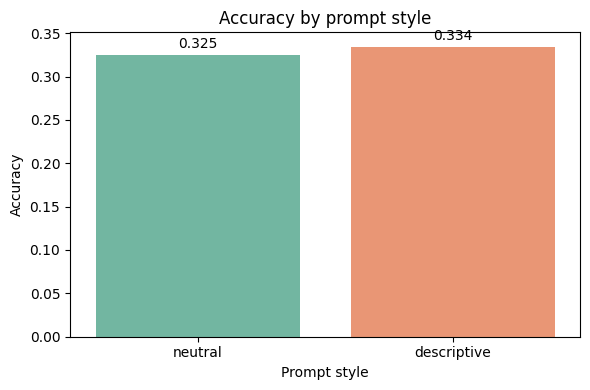

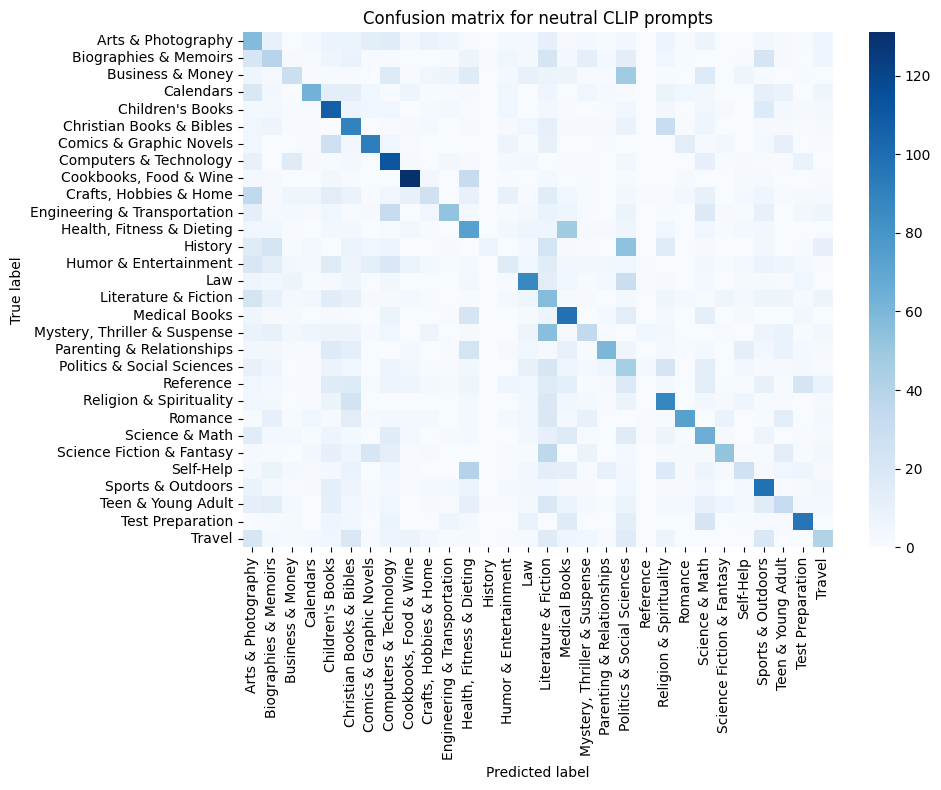

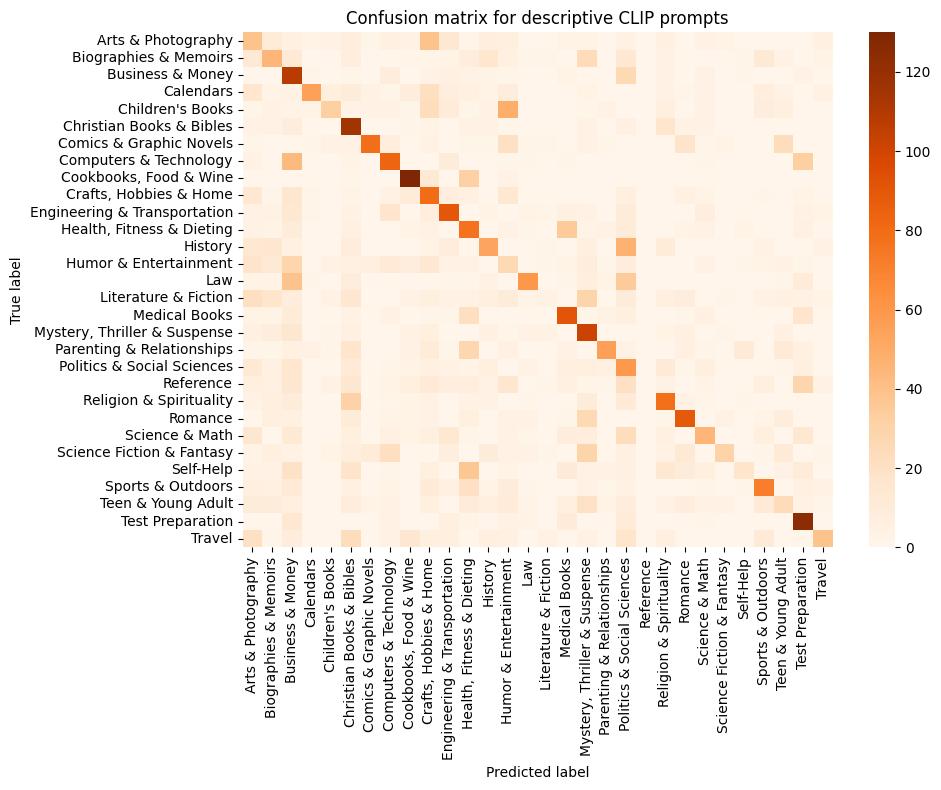

/var/folders/dg/npvld7kd5xl_h3l33d0lct6r0000gp/T/ipykernel_86331/920288882.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


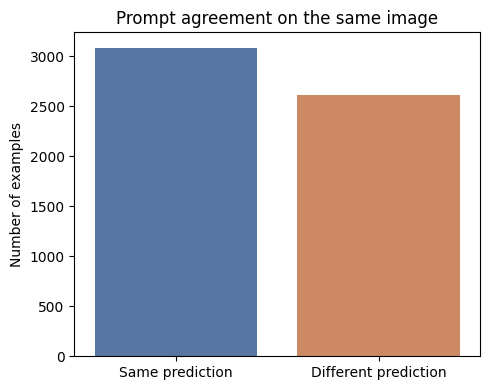

Example prompt disagreements:
         image                   true_label             neutral_pred             descriptive_pred
1576759202.jpg                    Reference     Literature & Fiction             Business & Money
0754823865.jpg                    Reference     Literature & Fiction Engineering & Transportation
B0008A3C7K.jpg                       Travel                   Travel     Christian Books & Bibles
0374104107.jpg Mystery, Thriller & Suspense       Arts & Photography       Cookbooks, Food & Wine
061574723X.jpg    Parenting & Relationships Christian Books & Bibles             Business & Money
1555218571.jpg        Humor & Entertainment  Comics & Graphic Novels       Cookbooks, Food & Wine
0465097626.jpg                    Self-Help     Literature & Fiction Mystery, Thriller & Suspense
1592408982.jpg                    Reference                   Travel        Humor & Entertainment
0393339157.jpg Engineering & Transportation                   Travel        Biographies 

In [43]:
# Compare prompt styles directly
comparison_df = (
    neutral_df[['image', 'true_label', 'predicted_label']]
    .rename(columns={'predicted_label': 'neutral_pred'})
    .merge(
        descriptive_df[['image', 'predicted_label']].rename(columns={'predicted_label': 'descriptive_pred'}),
        on='image',
        how='inner'
    )
)
comparison_df['changed_between_prompts'] = comparison_df['neutral_pred'] != comparison_df['descriptive_pred']
comparison_df['agreement'] = comparison_df['neutral_pred'] == comparison_df['descriptive_pred']

prompt_style_summary = pd.DataFrame({
    'prompt_style': ['neutral', 'descriptive'],
    'accuracy': [
        accuracy_score(neutral_df['true_label'], neutral_df['predicted_label']),
        accuracy_score(descriptive_df['true_label'], descriptive_df['predicted_label'])
    ],
    'changed_predictions': [
        int((comparison_df['neutral_pred'] != comparison_df['descriptive_pred']).sum()),
        int((comparison_df['neutral_pred'] != comparison_df['descriptive_pred']).sum())
    ]
})

plt.figure(figsize=(6, 4))
ax = sns.barplot(data=prompt_style_summary, x='prompt_style', y='accuracy', palette='Set2')
ax.set_title('Accuracy by prompt style')
ax.set_xlabel('Prompt style')
ax.set_ylabel('Accuracy')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'prompt_style_accuracy.png', dpi=200)
plt.show()

# Confusion matrix for the neutral prompt style
labels = sorted(set(CLASS_NAMES))
cm = confusion_matrix(neutral_df['true_label'], neutral_df['predicted_label'], labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_df, annot=False, cmap='Blues', cbar=True)
plt.title('Confusion matrix for neutral CLIP prompts')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix_neutral.png', dpi=200)
plt.show()

# Confusion matrix for the descriptive prompt style
descriptive_cm = confusion_matrix(descriptive_df['true_label'], descriptive_df['predicted_label'], labels=labels)
descriptive_cm_df = pd.DataFrame(descriptive_cm, index=labels, columns=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(descriptive_cm_df, annot=False, cmap='Oranges', cbar=True)
plt.title('Confusion matrix for descriptive CLIP prompts')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix_descriptive.png', dpi=200)
plt.show()

# Prompt agreement on the same image entries
agreement_counts = comparison_df['agreement'].value_counts().reindex([True, False], fill_value=0)

plt.figure(figsize=(5, 4))
ax = sns.barplot(
    x=['Same prediction', 'Different prediction'],
    y=[agreement_counts.get(True, 0), agreement_counts.get(False, 0)],
    palette=['#4C72B0', '#DD8452']
)
ax.set_title('Prompt agreement on the same image')
ax.set_ylabel('Number of examples')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'prompt_agreement.png', dpi=200)
plt.show()

# Show a few examples where prompt styles disagree
example_changes = comparison_df[comparison_df['changed_between_prompts']].head(10)
print('Example prompt disagreements:')
print(example_changes[['image', 'true_label', 'neutral_pred', 'descriptive_pred']].to_string(index=False))

# Top confusion pairs
def top_confusions(df):
    pairs = []
    for true_label in labels:
        for pred_label in labels:
            if true_label == pred_label:
                continue
            count = ((df['true_label'] == true_label) & (df['predicted_label'] == pred_label)).sum()
            if count > 0:
                pairs.append((true_label, pred_label, int(count)))
    return sorted(pairs, key=lambda x: x[2], reverse=True)[:10]

print('Top confusion pairs:')
for pair in top_confusions(neutral_df):
    print(pair)


In [44]:
# Save a compact summary table for report use
comparison_df = (
    neutral_df[['image', 'true_label', 'predicted_label']]
    .rename(columns={'predicted_label': 'neutral_pred'})
    .merge(
        descriptive_df[['image', 'predicted_label']].rename(columns={'predicted_label': 'descriptive_pred'}),
        on='image',
        how='inner'
    )
)
comparison_df['changed_between_prompts'] = comparison_df['neutral_pred'] != comparison_df['descriptive_pred']

summary_df = pd.DataFrame({
    'metric': [
        'overall_accuracy_neutral',
        'overall_accuracy_descriptive',
        'prediction_changes_between_prompts'
    ],
    'value': [
        accuracy_score(neutral_df['true_label'], neutral_df['predicted_label']),
        accuracy_score(descriptive_df['true_label'], descriptive_df['predicted_label']),
        int(comparison_df['changed_between_prompts'].sum())
    ]
})
summary_df.to_csv(OUTPUT_DIR / 'summary_metrics.csv', index=False)
print(summary_df)


                               metric        value
0            overall_accuracy_neutral     0.324737
1        overall_accuracy_descriptive     0.334211
2  prediction_changes_between_prompts  2613.000000


## Conclusion

In this notebook we explored how CLIP can perform zero-shot book-cover classification in a straightforward way, and the results are more or less what we have expected. Some genres are easy to separate from their covers, while others remain difficult because they share visual cues such as color palette, typography, or cover design conventions.

The focus was on comparison between neutral and descriptive prompts: wording changes can alter a prediction, especially for borderline examples. In several cases, the descriptive prompt appears to capture more semantic detail and improves the interpretation of the image, but it also shows that prompt engineering alone cannot fully remove confusion between related categories.

Overall, the experiment supports the idea that CLIP is a promising baseline for book-cover classification, especially since only zero-shot setup and slight changes to prompt wording were used here. In the next phase we (with the help of ai hopefully) would want to go deeper into the model, to identify where exactly misclassifications or biases (like for example darker colors for "Mystery, Thriller and Suspense" or yellow text on the cover for "Romance") come from and how to explain them.
